# Lecture 3 companion — a forecast is useful through a decision

**Time:** 15–20 minutes. **Question:** How many robot kits should we prepare before tomorrow's demand is known?

You will connect a prediction to an inventory decision, discover a ranking reversal between absolute error and operational cost, and compare policies on future days. Follow **predict → run → change → explain**. Supplied code runs as written; short prompts are for your notes.

This isolates one idea from the [Lab 6 production-cell capstone](https://github.com/AdoHaha/automation_robotics_lab/blob/3c1b7a70f5990d7665b11a7a853eaf1061a36d30/lab_auto_6.ipynb). Lab 6 trains forecasting/classification models and integrates blending, maintenance, scheduling, and project planning. This companion adds a single-period inventory decision and explicit uncertainty calibration; it does not require the lab's data or solvers.

**Run:** use a fresh Python 3 kernel and run all cells in order. NumPy, pandas, and Matplotlib are required; ipywidgets enables optional controls. Locally, install once with `python -m pip install numpy pandas matplotlib ipywidgets`. No downloads, accounts, or local data files are used. Direct function calls work when controls are unavailable.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (10, 3.6), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
SEED = 307
print("Synthetic teaching data; seed:", SEED)

Synthetic teaching data; seed: 307


## 1. Define the decision (2 minutes)

Choose integer quantity $q\geq0$ **before** demand $D$ is observed. One product, one day, no initial stock, no same-day replenishment, no carryover value. Demand is independent of our quantity and fully observed, including lost orders. Later we add a capacity limit.

Excess costs $c_o$ currency per unused kit; shortage costs $c_u$ currency per unserved kit:

$$L(q,D)=c_o\max(q-D,0)+c_u\max(D-q,0).$$

This is **mismatch loss**, not purchasing expenditure or total revenue. In a single-period profit model with sale price $p$, purchase cost $w$, and salvage $s$, use $c_u=p-w$, $c_o=w-s$; profit is $(p-w)D-L(q,D)$. With exogenous demand, minimizing expected loss maximizes expected profit.

**Predict:** With shortage costing nine times excess, should we prepare the mean demand or more? Write a reason before running.

In [2]:
def loss(q, demand, c_u=9.0, c_o=1.0):
    """Elementwise mismatch cost; NumPy broadcasting is intentional."""
    if c_u <= 0 or c_o <= 0:
        raise ValueError("Both marginal costs must be positive.")
    q, demand = np.asarray(q), np.asarray(demand)
    if np.any(q < 0) or np.any(demand < 0):
        raise ValueError("Quantities and demand must be nonnegative.")
    return c_o * np.maximum(q - demand, 0) + c_u * np.maximum(demand - q, 0)

assert loss(100, 120) == 180
assert loss(120, 100) == 20
assert loss(100, 100) == 0
print("q=100, D=120 → loss:", loss(100, 120))

q=100, D=120 → loss: 180.0


## 2. An exact counterexample (3 minutes)

Demand is 80, 100, or 120 kits with probabilities 0.25, 0.50, 0.25. These are stipulated probabilities, not a fitted distribution.

**Predict:** Compare outputs 100 and 120. Which wins on expected absolute error? Which wins on expected mismatch cost? Do the arithmetic for at least one row.

A point forecast and a decision quantify different targets. A median minimizes expected absolute error. For this loss, an optimal inventory quantity is a quantile with level $\alpha=c_u/(c_u+c_o)$. For integer demand, choose the smallest integer $q$ whose cumulative probability reaches $\alpha$.

In [3]:
demand = np.array([80, 100, 120])
probability = np.array([0.25, 0.50, 0.25])
assert np.isclose(probability.sum(), 1)
quantities = np.arange(0, 151)
expected_cost = loss(quantities[:, None], demand) @ probability
expected_mae = np.abs(quantities[:, None] - demand) @ probability

comparison = pd.DataFrame({
    "quantity (kits)": [100, 120],
    "expected absolute error (kits)": expected_mae[[100, 120]],
    "expected cost (currency/day)": expected_cost[[100, 120]],
    "stockout-day probability": [(demand > q) @ probability for q in [100, 120]],
})
print(comparison.to_string(index=False))
q_cost = int(quantities[np.argmin(expected_cost)])
q_mae = int(quantities[np.argmin(expected_mae)])
assert (q_mae, q_cost) == (100, 120)
assert np.allclose(expected_cost[[100, 120]], [50, 20])
assert np.allclose(expected_mae[[100, 120]], [10, 20])
# A separate calculation verifies the optimizer by the exact quantile rule.
alpha = 9 / (9 + 1)
q_quantile = int(demand[np.searchsorted(np.cumsum(probability), alpha)])
assert q_quantile == q_cost
print(f"Absolute-error optimum: {q_mae}; cost optimum: {q_cost}; target quantile: {alpha:.0%}")

 quantity (kits)  expected absolute error (kits)  expected cost (currency/day)  stockout-day probability
             100                            10.0                          50.0                      0.25
             120                            20.0                          20.0                      0.00
Absolute-error optimum: 100; cost optimum: 120; target quantile: 90%


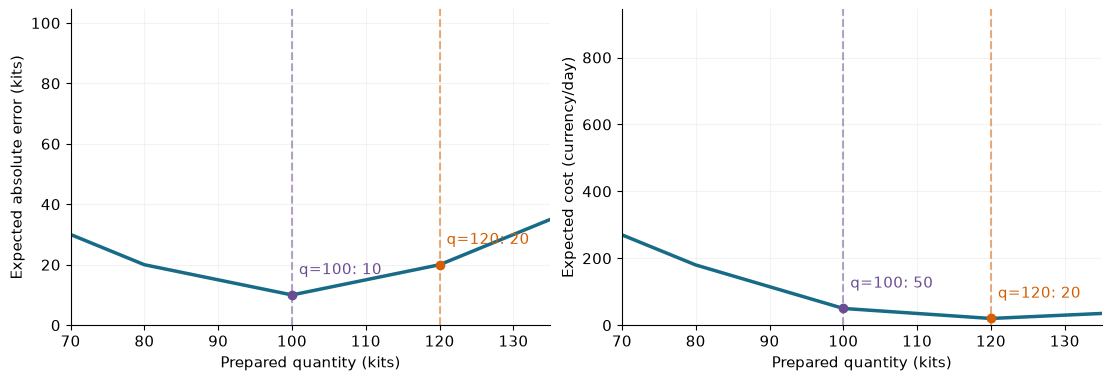

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), constrained_layout=True)
for ax, values, ylabel in zip(axes, [expected_mae, expected_cost],
    ["Expected absolute error (kits)", "Expected cost (currency/day)"]):
    ax.plot(quantities, values, color="#176b87", linewidth=2.5)
    for q, color in [(100, "#6a4c93"), (120, "#d55e00")]:
        ax.axvline(q, color=color, linestyle="--", alpha=.5)
        ax.scatter(q, values[q], color=color, zorder=3)
        ax.annotate(f"q={q}: {values[q]:g}", (q, values[q]), xytext=(5, 15),
                    textcoords="offset points", color=color)
    ax.set(xlim=(70, 135), ylim=(0, None), xlabel="Prepared quantity (kits)", ylabel=ylabel)
    ax.grid(alpha=.15)
plt.show()

**Explain:** Output 100 wins on MAE (10 versus 20 kits), but quantity 120 wins on cost (20 versus 50 currency/day). This is not evidence that a biased model is universally better: the outputs serve different targets.

A service metric also needs a definition. For $q=100$, demand exceeds stock on 25% of days, but only 5 units/day go unserved on average. Cycle service is 75%; unit fill rate is $1-5/100=95\%$. A 90th-percentile rule does not promise a 90% fill rate. Discrete distributions can also exceed their nominal quantile coverage.

## 3. Change costs, uncertainty, and capacity (4 minutes)

The next experiment draws 4,000 possible demands around 100 kits. We reuse the **same fixed standard-normal draws** at every slider setting so a movement reflects your parameter change. Round and clip demand to nonnegative integers. This is a synthetic scenario model, not a fitted or calibrated forecast.

**Predict:** What happens to the best quantity if shortage costs increase? If demand noise increases? If capacity falls below the desired quantity?

The function enumerates **every feasible integer quantity** and minimizes mean loss across its scenarios. It reports the finite-scenario optimum, not an exact population optimum. Capacity can make low stockout risk unattainable.

Target quantile: 90.0%; feasible best q: 120 kits
Scenario mean cost: 27.41; stockout days: 8.9%; unit fill: 99.3%


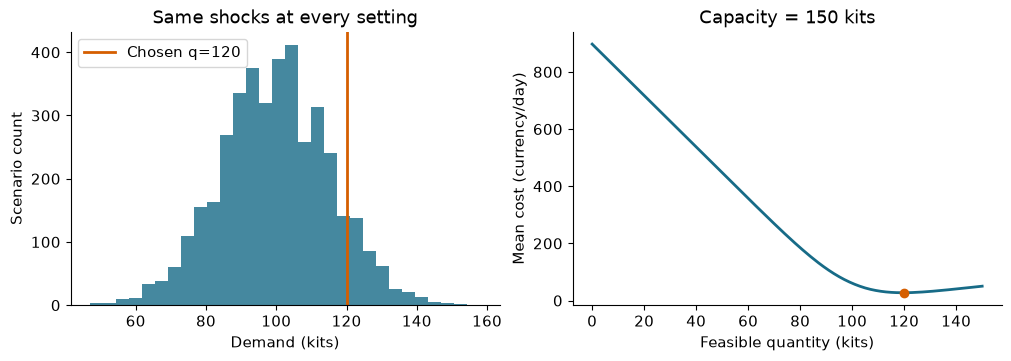

In [5]:
fixed_shocks = np.random.default_rng(SEED).normal(size=4000)

def inventory_experiment(c_u=9.0, sigma=15.0, capacity=150):
    if sigma < 0 or int(capacity) != capacity or capacity < 0:
        raise ValueError("Noise must be nonnegative and capacity a nonnegative integer.")
    scenarios = np.maximum(0, np.rint(100 + sigma * fixed_shocks)).astype(int)
    grid = np.arange(int(capacity) + 1)
    costs = loss(grid[:, None], scenarios, c_u=c_u).mean(axis=1)
    chosen = int(grid[np.argmin(costs)])
    stockout = np.mean(scenarios > chosen)
    unmet = np.maximum(scenarios - chosen, 0).mean()
    fill_rate = 1 - unmet / scenarios.mean()
    print(f"Target quantile: {c_u / (c_u + 1):.1%}; feasible best q: {chosen} kits")
    print(f"Scenario mean cost: {costs[chosen]:.2f}; stockout days: {stockout:.1%}; "
          f"unit fill: {fill_rate:.1%}")
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
    axes[0].hist(scenarios, bins=30, color="#176b87", alpha=.8)
    axes[0].axvline(chosen, color="#d55e00", label=f"Chosen q={chosen}", linewidth=2)
    axes[0].set(xlabel="Demand (kits)", ylabel="Scenario count", title="Same shocks at every setting")
    axes[0].legend()
    axes[1].plot(grid, costs, color="#176b87", linewidth=2)
    axes[1].scatter(chosen, costs[chosen], color="#d55e00", zorder=3)
    axes[1].set(xlabel="Feasible quantity (kits)", ylabel="Mean cost (currency/day)",
                title=f"Capacity = {capacity} kits")
    plt.show()
    return {"quantity": chosen, "cost": float(costs[chosen]), "stockout": float(stockout)}

# Baseline always runs, even without widgets.
baseline_result = inventory_experiment(c_u=9.0, sigma=15.0, capacity=150)
assert baseline_result["quantity"] <= 150

In [6]:
# Optional controls. If they do not render, edit the direct function call above.
try:
    import ipywidgets as widgets
except ImportError:
    print("ipywidgets is unavailable; use inventory_experiment(c_u=3, sigma=25, capacity=110).")
else:
    def show_inventory(c_u, sigma, capacity):
        inventory_experiment(c_u=c_u, sigma=sigma, capacity=capacity)
    controls = widgets.interactive(
        show_inventory,
        c_u=widgets.FloatSlider(value=9, min=.5, max=20, step=.5,
                               description="Shortage cost", continuous_update=False,
                               style={"description_width": "initial"}),
        sigma=widgets.FloatSlider(value=15, min=0, max=35, step=1,
                                 description="Demand noise", continuous_update=False,
                                 style={"description_width": "initial"}),
        capacity=widgets.IntSlider(value=150, min=80, max=180, step=5,
                                  description="Capacity", continuous_update=False),
    )
    display(controls)

interactive(children=(FloatSlider(value=9.0, continuous_update=False, description='Shortage cost', max=20.0, m…

Record three experiments, then explain the mechanism. Keep excess cost fixed at 1 currency/kit.

| Change | Predicted quantity direction | Actual quantity | Mean cost | Explanation |
|---|---|---|---|---|
| Shortage cost 9 → 2 | | | | |
| Noise 15 → 30 | | | | |
| Capacity 150 → 100 | | | | |

Noise need not raise the optimum when costs are symmetric, and a binding capacity can hide the desired change. Check the full curve rather than assuming every slider has a monotone effect on every metric.

## 4. Learn from the past, evaluate in the future (5 minutes)

Now generate 300 chronological days. Tomorrow's weekday and a **confirmed promotion** are known when quantity is committed. Random demand shocks are not. Both predictors use only known information:

- **Constant:** training mean demand.
- **Calendar + promotion:** least-squares regression using weekday sine/cosine and the announced promotion flag.

A simple uncertainty policy adds a quantile of **later calibration residuals** to each point prediction. It assumes residual distributions transfer across contexts and time. We keep four roles separate:

| Days (positions) | Role | Allowed use |
|---|---|---|
| 0–119 | Training | Fit predictor coefficients |
| 120–179 | Calibration | Estimate each predictor's residual quantile |
| 180–239 | Validation | Select one complete inventory policy |
| 240–299 | Test | Report the frozen policy once |

This is a one-day-ahead policy with frozen fitted parameters. The sine/cosine features encode weekly seasonality without treating Sunday and Monday as far apart. For policies with more hyperparameters, repeat the chronology with rolling origins; a single split is only a small teaching demonstration.

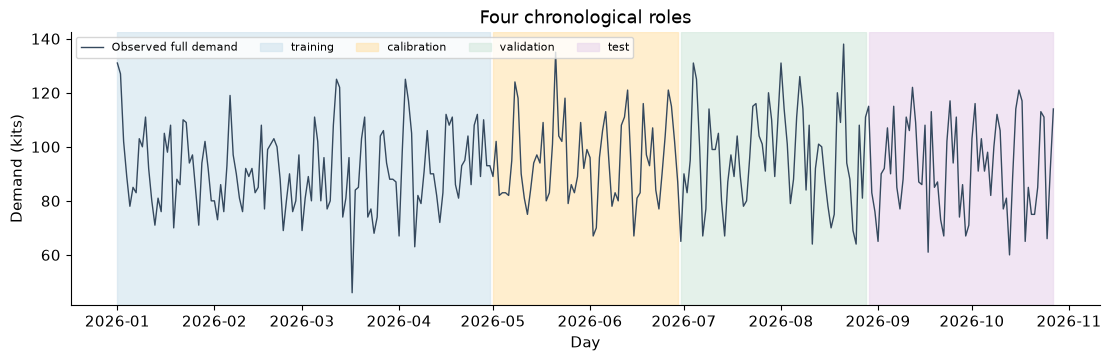

In [7]:
rng = np.random.default_rng(SEED + 1)
n_days = 300
t = np.arange(n_days)
promo = ((t % 23) < 3).astype(float)  # Confirmed plan, not future realized sales.
X = np.column_stack([np.ones(n_days), np.sin(2 * np.pi * t / 7),
                     np.cos(2 * np.pi * t / 7), promo])
mean_demand = X @ np.array([90.0, 12.0, 7.0, 20.0])
y = np.maximum(0, np.rint(mean_demand + rng.normal(0, 12, n_days))).astype(int)
data = pd.DataFrame({"date": pd.date_range("2026-01-01", periods=n_days),
                     "demand": y, "confirmed_promotion": promo.astype(int)})
blocks = {"training": np.arange(0, 120), "calibration": np.arange(120, 180),
          "validation": np.arange(180, 240), "test": np.arange(240, 300)}
assert blocks["training"][-1] < blocks["calibration"][0]
assert blocks["calibration"][-1] < blocks["validation"][0]
assert blocks["validation"][-1] < blocks["test"][0]
assert len(np.unique(np.concatenate(list(blocks.values())))) == n_days

fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
ax.plot(data.date, y, color="#35495e", linewidth=1, label="Observed full demand")
for (name, idx), color in zip(blocks.items(), ["#d3e5ef", "#ffe5b4", "#d6eadf", "#ead8ed"]):
    ax.axvspan(data.date.iloc[idx[0]], data.date.iloc[idx[-1]], color=color, alpha=.65, label=name)
ax.set(xlabel="Day", ylabel="Demand (kits)", title="Four chronological roles")
ax.legend(ncol=5, fontsize=8, loc="upper left")
plt.show()

In [8]:
train_idx = blocks["training"]
cal_idx = blocks["calibration"]
coefficients, *_ = np.linalg.lstsq(X[train_idx], y[train_idx], rcond=None)
point_predictions = {
    "constant": np.full(n_days, y[train_idx].mean()),
    "calendar + promotion": X @ coefficients,
}
C_U, C_O, CAPACITY = 9.0, 1.0, 150
ALPHA = C_U / (C_U + C_O)

# For every fitted predictor, calibrate one residual quantile on its own block.
residual_offsets = {
    name: float(np.quantile(y[cal_idx] - prediction[cal_idx], ALPHA,
                            method="inverted_cdf"))
    for name, prediction in point_predictions.items()
}

# Operational convention: round up to whole kits, then enforce capacity.
# This is an approximate residual-distribution policy, not an optimality theorem.
policies = {}
for name, prediction in point_predictions.items():
    policies[name + " / point"] = np.clip(np.ceil(prediction), 0, CAPACITY).astype(int)
    policies[name + " / quantile"] = np.clip(
        np.ceil(prediction + residual_offsets[name]), 0, CAPACITY).astype(int)
assert all(np.all((q >= 0) & (q <= CAPACITY)) for q in policies.values())
print("Quantile offsets learned on calibration days (kits):")
print(pd.Series(residual_offsets).round(2).to_string())

Quantile offsets learned on calibration days (kits):
constant                24.60
calendar + promotion    20.07


**Read the distinction:** `point_predictions` estimates demand; `policies` chooses feasible quantities. The `/ point` policy uses the point output as if demand were certain. The `/ quantile` policy accounts for empirical uncertainty. Rounding up is a simple operational convention; with a fully specified distribution, enumerate feasible integers as in Section 3.

**Predict:** Does adding stock improve point-forecast MAE? Must it improve decision cost? Which score should select the operating policy?

In [9]:
def score_policies(indices):
    rows = []
    actual = y[indices]
    for name, q_all in policies.items():
        q = q_all[indices]
        unserved = np.maximum(actual - q, 0)
        rows.append({"policy": name,
            "quantity MAE (kits)": np.mean(np.abs(q - actual)),
            "cost/day": np.mean(loss(q, actual, C_U, C_O)),
            "stockout days": np.mean(actual > q),
            "unserved units/day": unserved.mean(),
            "excess units/day": np.maximum(q - actual, 0).mean(),
            "unit fill rate": 1 - unserved.sum() / actual.sum()})
    return pd.DataFrame(rows).set_index("policy")

validation_scores = score_policies(blocks["validation"])
selected_policy = str(validation_scores["cost/day"].idxmin())
print("VALIDATION: used to select the complete policy")
print(validation_scores.round(3).to_string())
print("Frozen policy chosen by validation cost:", selected_policy)

# Demand-prediction MAE is scored separately from chosen-quantity MAE.
forecast_mae = {name: np.mean(np.abs(pred[blocks["validation"]] - y[blocks["validation"]]))
                for name, pred in point_predictions.items()}
print("\nValidation point-forecast MAE (kits):", {k: round(v, 2) for k, v in forecast_mae.items()})

VALIDATION: used to select the complete policy
                                 quantity MAE (kits)  cost/day  stockout days  unserved units/day  excess units/day  unit fill rate
policy                                                                                                                             
constant / point                              15.383    94.183          0.550               9.850             5.533           0.898
constant / quantile                           22.317    32.850          0.117               1.317            21.000           0.986
calendar + promotion / point                  10.483    69.683          0.583               7.400             3.083           0.923
calendar + promotion / quantile               17.167    23.033          0.117               0.733            16.433           0.992
Frozen policy chosen by validation cost: calendar + promotion / quantile

Validation point-forecast MAE (kits): {'constant': np.float64(15.46), 'calendar + promo

TEST: descriptive comparison on untouched later days
                                 quantity MAE (kits)  cost/day  stockout days  unserved units/day  excess units/day  unit fill rate
policy                                                                                                                             
constant / point                              14.850    76.983          0.433               7.767             7.083           0.916
constant / quantile                           23.750    25.483          0.067               0.217            23.533           0.998
calendar + promotion / point                  10.583    59.517          0.567               6.117             4.467           0.934
calendar + promotion / quantile               18.683    20.017          0.033               0.167            18.517           0.998

Preselected policy's test cost: 20.02
This is a finite-sample backtest, not a guarantee or causal field result.


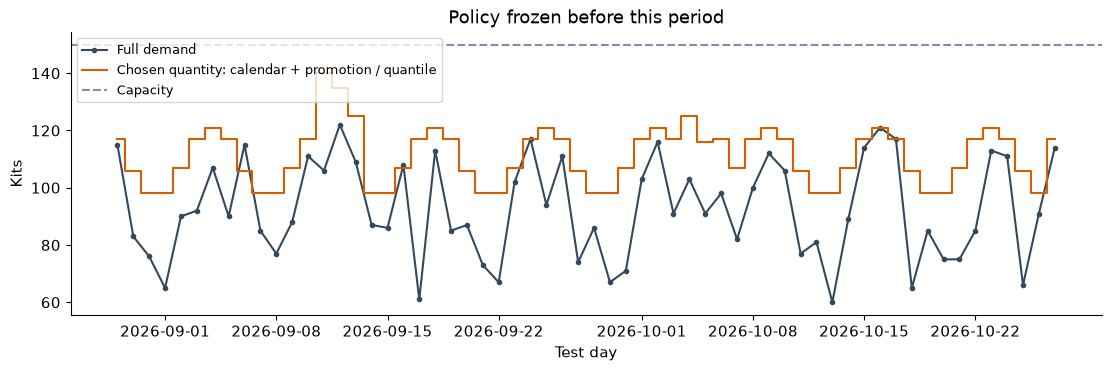

In [10]:
# Final reporting block: do not use its output to change coefficients, offsets, or policy selection.
test_scores = score_policies(blocks["test"])
print("TEST: descriptive comparison on untouched later days")
print(test_scores.round(3).to_string())
print("\nPreselected policy's test cost:", round(test_scores.loc[selected_policy, "cost/day"], 2))
print("This is a finite-sample backtest, not a guarantee or causal field result.")

idx = blocks["test"]
fig, ax = plt.subplots(figsize=(11, 3.6), constrained_layout=True)
ax.plot(data.date.iloc[idx], y[idx], color="#35495e", label="Full demand", marker=".")
ax.step(data.date.iloc[idx], policies[selected_policy][idx], where="mid",
        color="#d55e00", label="Chosen quantity: " + selected_policy)
ax.axhline(CAPACITY, color="#6a4c93", linestyle="--", alpha=.7, label="Capacity")
ax.set(xlabel="Test day", ylabel="Kits", title="Policy frozen before this period")
ax.legend(fontsize=9, loc="upper left")
plt.show()

## 5. Explain what the demonstration does and does not show (2 minutes)

Write one sentence for each:

1. What question does MAE answer, and what question does mismatch cost answer?
2. Why are residuals calibrated after predictor training? Why is a further validation block used before the final test?
3. A colleague proposes `rolling(7).mean()` of demand including the target day as a feature. Which information leaks? How would `shift(1)` change the information set?
4. If observed sales equal $\min(D,q)$, why would treating sales as full demand underestimate demand after stockouts?
5. If a new promotion doubles the variance but not the mean, why might a single residual offset fail?

**Optional extension (separate experiment):** make a copy of the notebook before changing the data-generating process, add a demand shift to the final block, and rerun. Label this a stress scenario rather than using it to repeatedly tune the original test result.

A finite-sample ranking may differ from the exact scenario ranking in Section 2. The calibration estimate can be noisy, capacities bind, and fitted errors need not transfer. These are reasons to investigate model assumptions, not reasons to promise a gain.

## Instructor notes and sources

Expected core observations:

- Exact example: `q=100` has MAE 10 and cost 50; `q=120` has MAE 20 and cost 20.
- Increasing shortage cost raises the target quantile; tight capacity truncates the feasible choice.
- Symmetric shortage/excess cost targets a median, whereas 9:1 targets the 90th percentile.
- The calendar predictor can exploit features known before commitment; no complex ML package is necessary to illustrate the pipeline.
- Calibration fits uncertainty, validation selects a complete policy, and the test block is reporting only. In real deployment, apply the same information rules at rolling cutoffs.

References (checked for the lecture revision):

- [MIT OpenCourseWare: Newsvendor Inventory Problem](https://ocw.mit.edu/courses/15-772j-d-lab-supply-chains-fall-2014/6952be57b43aa185119c6f114908bcc5_MIT15_772JF14_Newsboy.pdf), single-period assumptions and critical ratio.
- [Hyndman and Athanasopoulos: The forecaster's toolbox](https://otexts.com/fpp3/toolbox.html), forecast accuracy, quantile scores, and time series cross-validation.
- [Elmachtoub and Grigas: Smart “Predict, then Optimize”](https://arxiv.org/abs/1710.08005), motivation for accounting for downstream decisions when learning predictions.

All kit data, costs, and scenarios in this notebook are synthetic teaching examples, not measured industrial results.